# Get the lay of the land

In [1]:
import pandas as pd
data =  pd.read_csv(r"W:\Storage\Users\Huzefa\Work\Swotting\Jupyter Notebook\Machine Learning Jupyter notebook\End-To-End Projects\Fake Job Posting\fake_job_postings.csv")

In [2]:
data.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [3]:
data.describe()

,job_id,telecommuting,has_company_logo,has_questions,fraudulent
count,17880.000000,17880.000000,17880.000000,17880.000000,17880.000000
mean,8940.500000,0.042897,0.795302,0.491723,0.048434
std,5161.655742,0.202631,0.403492,0.499945,0.214688
min,1.000000,0.000000,0.000000,0.000000,0.000000
25%,4470.750000,0.000000,1.000000,0.000000,0.000000
50%,8940.500000,0.000000,1.000000,0.000000,0.000000
75%,13410.250000,0.000000,1.000000,1.000000,0.000000
max,17880.000000,1.000000,1.000000,1.000000,1.000000


In [4]:
data.columns

Index(['job_id', 'title', 'location', 'department', 'salary_range',
       'company_profile', 'description', 'requirements', 'benefits',
       'telecommuting', 'has_company_logo', 'has_questions', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function',
       'fraudulent'],
      dtype='object')

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

In [6]:
data.shape

(17880, 18)

In [7]:
data.isnull().sum()

job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64

#### View Text Data

In [8]:
data[['title', 'company_profile', 'description', 'requirements', 'benefits']].sample(3).T

,16273,17293,10524
title,Receptionist/Office Clerk,Talent Manager,Technical Writer (m/f)
company_profile,"""Our mission to our clients is to preserve the...",Intercom (#URL_cb674f93cbcd215a3a0a57a8615a565...,Pioneering advanced analytics vendor RapidMine...
description,Home Sweet Home In-Home Care is leading Southw...,About the roleIntercom (#URL_20af2fe8ac053b6b0...,Pioneering advanced analytics vendor RapidMine...
requirements,Qualifications IncludePrevious office experien...,This is a very people-focused position represe...,Master-Degree in related field Relevant work e...
benefits,NaN,"Benefits include a competitive salary, stock o...","In addition to an attractive salary, we offer ..."


### Check Class Imbalance

In [9]:
# The class is highly imbalanced
data['fraudulent'].value_counts()

fraudulent
0    17014
1      866
Name: count, dtype: int64

In [10]:
#Find out if the data is redundant/has duplicate values
data.duplicated().sum()

0

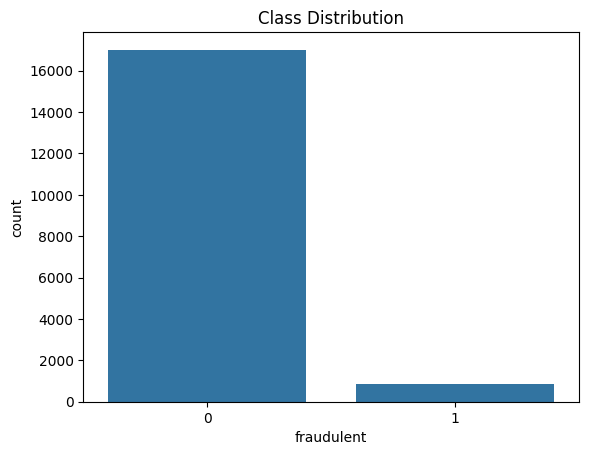

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='fraudulent', data=data)
plt.title("Class Distribution")
plt.show()

In [12]:
#1338 unique department values
data["department"].unique()

array(['Marketing', 'Success', nan, ..., 'Admin - Clerical',
       'Administrative Dept', 'Hospitality'], dtype=object)

In [13]:
data["location"].unique()

array(['US, NY, New York', 'NZ, , Auckland', 'US, IA, Wever', ...,
       'US, CA, los Angeles', 'CA, , Ottawa', 'GB, WSX, Chichester'],
      dtype=object)

In [14]:
country = []
for i in data["location"].unique():
    if type(i) == str:
        country.append(i.split()[0])

In [15]:
len(country)

3105

In [16]:
len(set(country))

105

In [17]:
data["company_profile"].unique().shape

(1710,)

In [18]:
profile_counts = {}

for info in data["company_profile"]:
    if info in profile_counts:
        profile_counts[info] += 1
    else:
        profile_counts[info] = 1

In [19]:
profile_counts

{"We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.We have a top editorial, business, and engineering team. We're focused on using technology to find new and better ways to connect people around their specific food interests, and to offer them superb, highly curated information about food and cooking. We attract the most talented home cooks and contributors in the country; we also publish well-known professionals like Mario Batali, Gwyneth Paltrow, and Danny Meyer. And we have partnerships with Whole Foods Market and Random House.Food52 has been named the best food website by the James Beard Foundation and IACP, and has been featured in the New York Times, NPR, Pando Daily, TechCrunch, and on the Today Show.We're located in Chelsea, in New York City.": 41,
 '90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cloud Video Production Se

### Viewing and Imputing missing values

In [20]:
# Percentage missing
(data.isna().sum()/17880)*100

job_id                  0.000000
title                   0.000000
location                1.935123
department             64.580537
salary_range           83.959732
company_profile        18.501119
description             0.005593
requirements           15.078300
benefits               40.335570
telecommuting           0.000000
has_company_logo        0.000000
has_questions           0.000000
employment_type        19.412752
required_experience    39.429530
required_education     45.329978
industry               27.421700
function               36.101790
fraudulent              0.000000
dtype: float64

In [21]:
data["department"].value_counts().head(10)

department
Sales                     551
Engineering               487
Marketing                 401
Operations                270
IT                        225
Development               146
Product                   112
Information Technology     86
Design                     76
Technology                 76
Name: count, dtype: int64

Dropping Salary Range and department because they're mostly blank

In [22]:
data.drop(columns="salary_range", inplace=True)
data.drop(columns="department", inplace=True)

In [23]:
cat_cols = ["employment_type", "required_experience", "required_education", "industry", "function", "location"]
text_cols = ["company_profile", "requirements", "benefits"]

for col in cat_cols:
    data[col].fillna("unknown", inplace=True)
    
for col in text_cols:
    data[col].fillna("", inplace=True)

In [24]:
data.isna().sum()

job_id                 0
title                  0
location               0
company_profile        0
description            1
requirements           0
benefits               0
telecommuting          0
has_company_logo       0
has_questions          0
employment_type        0
required_experience    0
required_education     0
industry               0
function               0
fraudulent             0
dtype: int64

In [25]:
data = data[~data["description"].isnull()]

In [26]:
data["text"] = data["title"] + " " + data["company_profile"] + " " + data["description"] + " " + data["requirements"] + " " + data["benefits"] + " "

To Do: Change all words into lowercase before doing any sort of EDA

In [27]:
data.drop(["title", "company_profile" ,"description","requirements" , "benefits"], axis=1, inplace=True)

In [28]:
data.head()

,job_id,location,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,text
0,1,"US, NY, New York",0,1,0,Other,Internship,unknown,unknown,Marketing,0,"Marketing Intern We're Food52, and we've creat..."
1,2,"NZ, , Auckland",0,1,0,Full-time,Not Applicable,unknown,Marketing and Advertising,Customer Service,0,Customer Service - Cloud Video Production 90 S...
2,3,"US, IA, Wever",0,1,0,unknown,unknown,unknown,unknown,unknown,0,Commissioning Machinery Assistant (CMA) Valor ...
3,4,"US, DC, Washington",0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0,Account Executive - Washington DC Our passion ...
4,5,"US, FL, Fort Worth",0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0,Bill Review Manager SpotSource Solutions LLC i...


In [29]:
set(data["text"][1].split())

{'#URL_395a8683a907ce95f49a12fb240e6e47ad8d5a4f96d07ebbd869c4dd4dea1826#',
 '&amp;',
 '(or',
 '-',
 '...And',
 '/',
 '100%',
 '100%.',
 '18th',
 '2,000',
 '2014',
 '30',
 '4,000',
 '5',
 '50',
 '500',
 '5pm',
 '60-90',
 '90',
 'A',
 'Account',
 'After',
 'Auckland',
 'Auckland,',
 'Awesome!Do',
 'Barclays',
 'CV.',
 'Cloud',
 'Countries',
 'Customer',
 'DUE',
 'Draft',
 'Fast,',
 'Focused',
 'Global',
 'GridAKL!',
 'Humour',
 'Innovation',
 "It's",
 'It’s',
 'July',
 "L'oreal,",
 'Live',
 'London,',
 'L’Oreal,',
 'Management?',
 'Manager',
 'Maybe',
 'NZ',
 'Once',
 'Organised',
 'Paypal,',
 'Please',
 'Precinct',
 'Production',
 'Project',
 'Quarter',
 'Seconds',
 'Seconds,',
 'Serious',
 'Service',
 'Service.90',
 'Singapore.Our',
 'Singapore.http://90#URL_fbe6559afac620a3cd2c22281f7b8d0eef56a73e3d9a311e2f1ca13d081dd630#',
 'Slick',
 'Sony',
 'Sydney,',
 'The',
 'Then',
 'Therefore,',
 'Tokyo',
 'VIDEOBeing',
 'Vibrant',
 'Video',
 'Vimeo',
 'We',
 'Wednesday',
 'What',
 'With',
 'Wo

# Visualization

### Unstratified Data

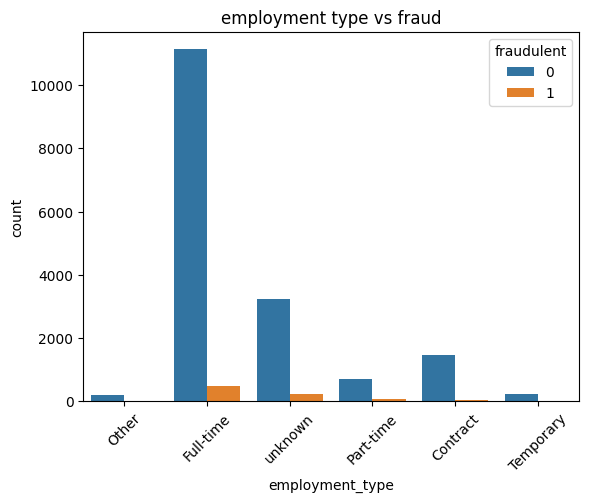

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="employment_type", hue="fraudulent", data=data)
plt.xticks(rotation=45)
plt.title("employment type vs fraud")
plt.show()

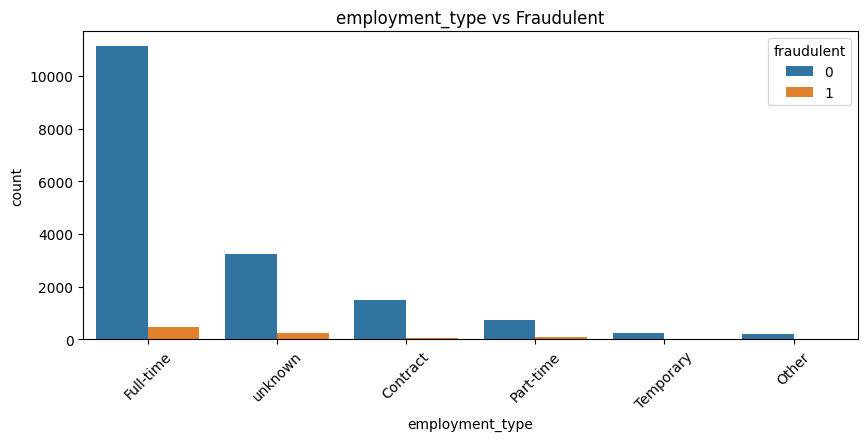

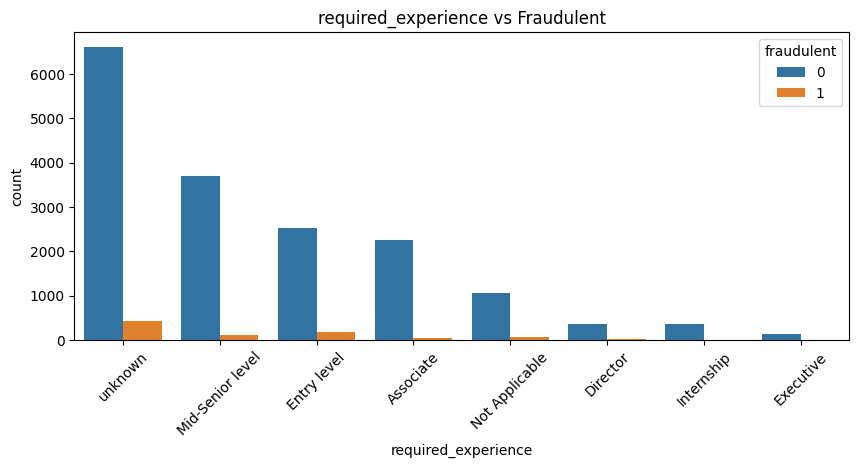

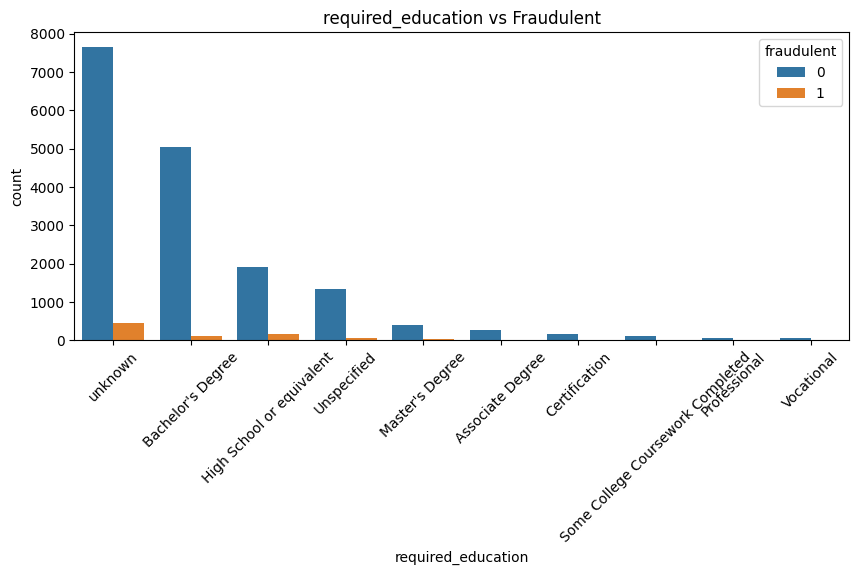

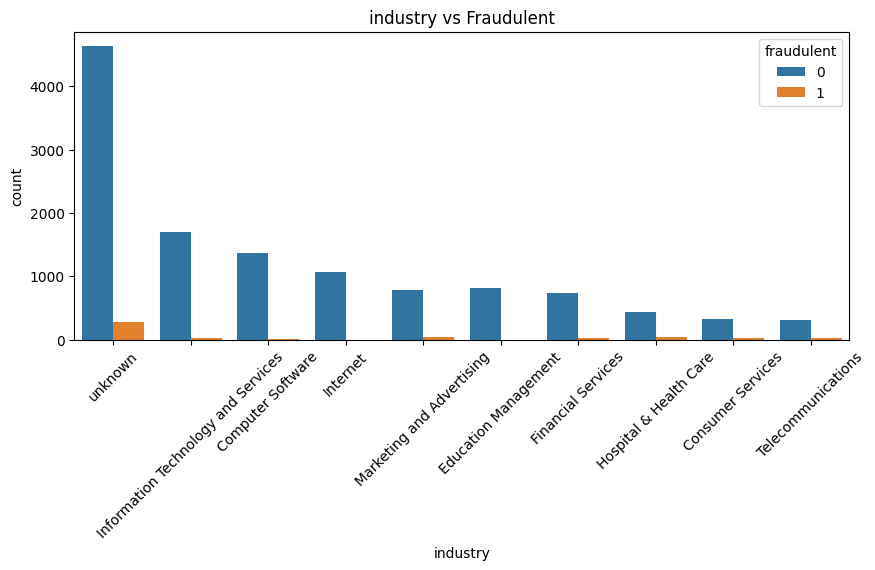

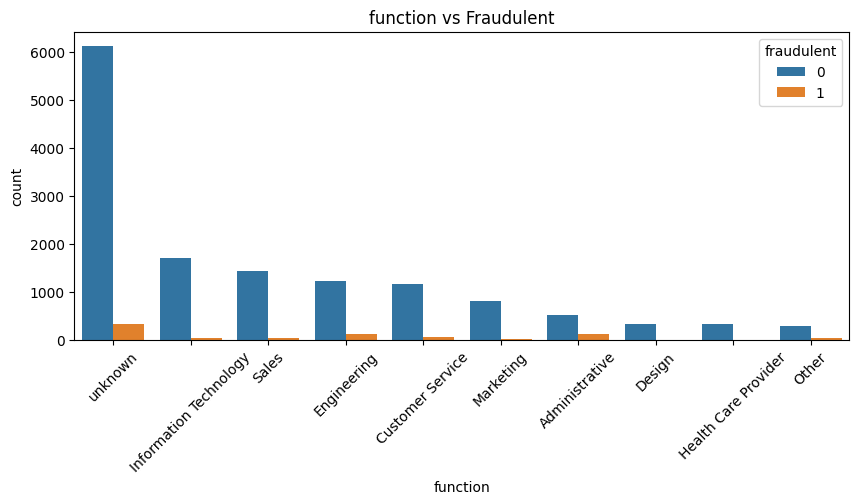

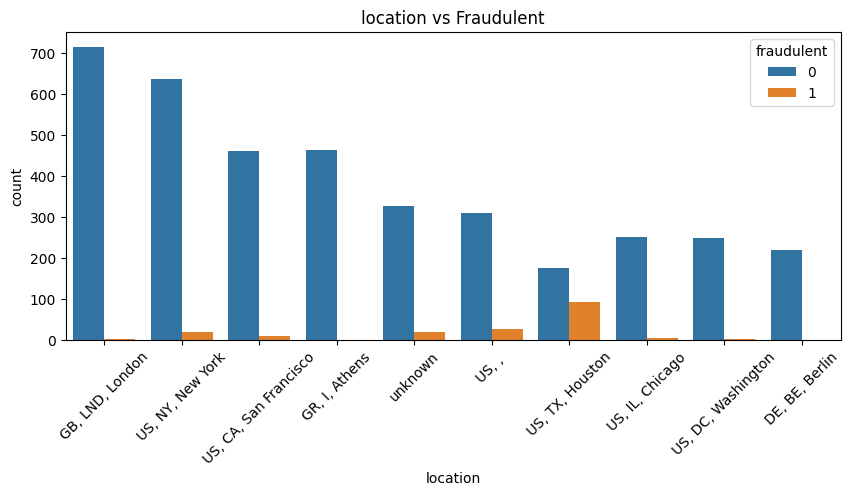

In [31]:
for col in cat_cols:
    plt.figure(figsize=(10, 4))
    sns.countplot(data=data, x=col, hue='fraudulent', order=data[col].value_counts().index[:10])
    plt.xticks(rotation=45)
    plt.title(f"{col} vs Fraudulent")
    plt.show()

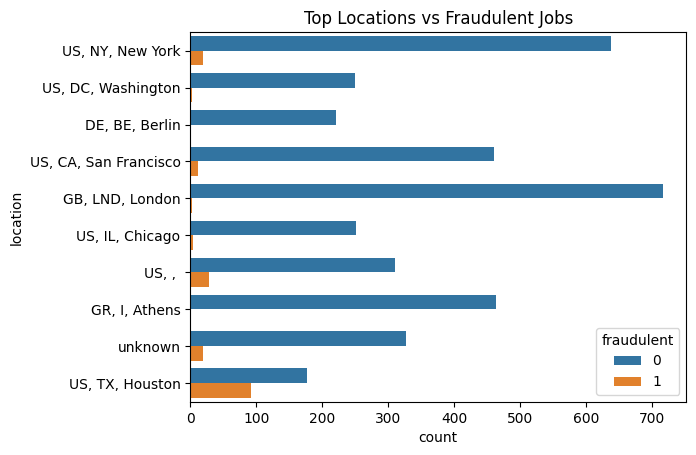

In [32]:
top_locations = data['location'].value_counts().head(10).index
sns.countplot(y='location', data=data[data['location'].isin(top_locations)], hue='fraudulent')
plt.title("Top Locations vs Fraudulent Jobs")
plt.show()

### Stratified Random Sampling
The data is imbalanced which is creating a problem for us to properly visualize patterns, let's divide the data into groups and randomly sample it

In [33]:
# Using python logic

data_real = data[data["fraudulent"] == 0]
data_fake = data[data["fraudulent"] == 1]


In [34]:
data_real.shape, data_fake.shape

((17014, 12), (865, 12))

In [35]:
random_real = data_real.sample(n=len(data_fake), random_state=42)
data_balanced = pd.concat((data_fake, random_real))

In [36]:
data[data["fraudulent"] == 0].index

Index([    0,     1,     2,     3,     4,     5,     6,     7,     8,     9,
       ...
       17870, 17871, 17872, 17873, 17874, 17875, 17876, 17877, 17878, 17879],
      dtype='int64', length=17014)

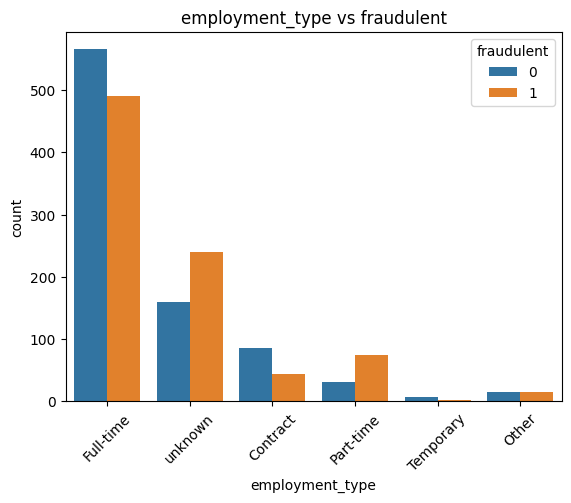

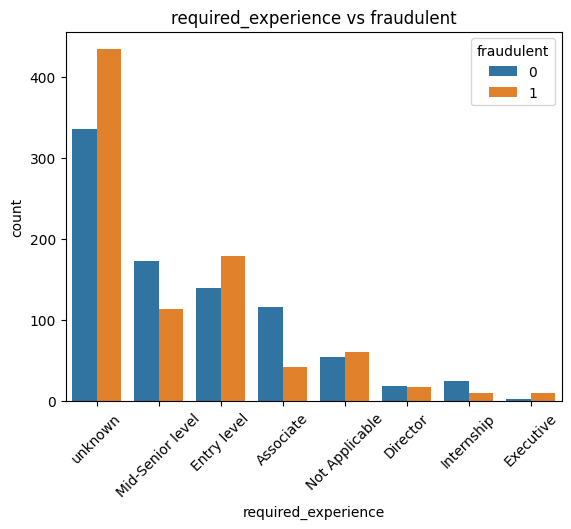

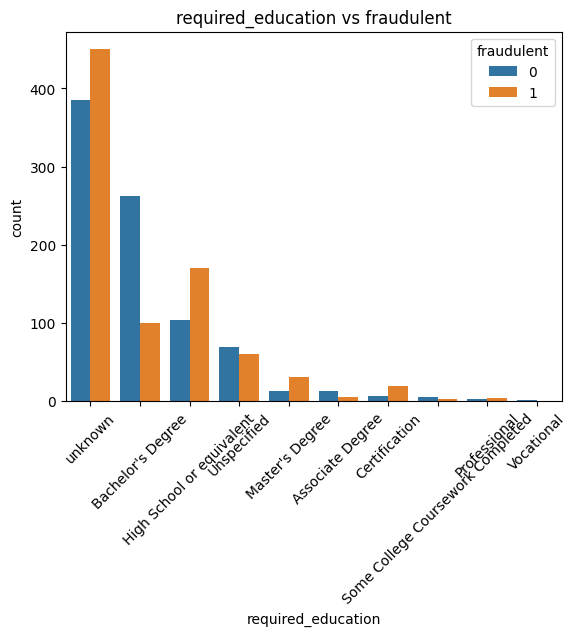

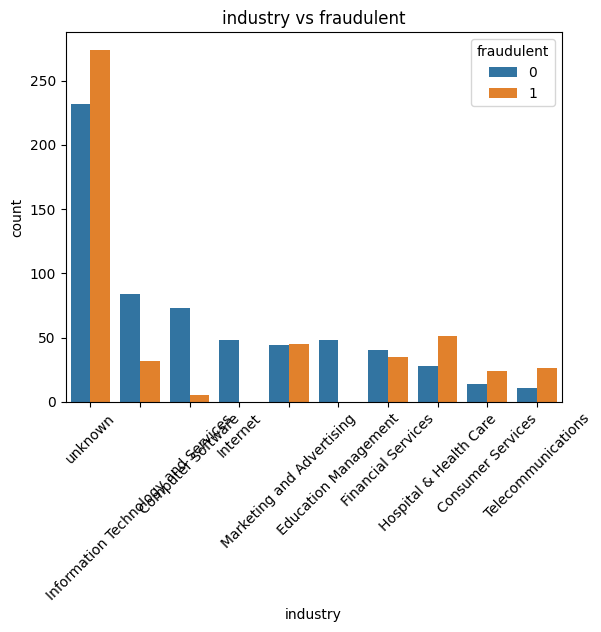

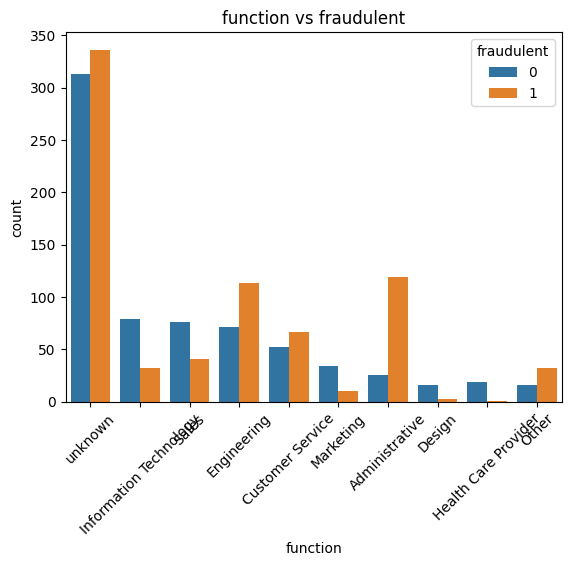

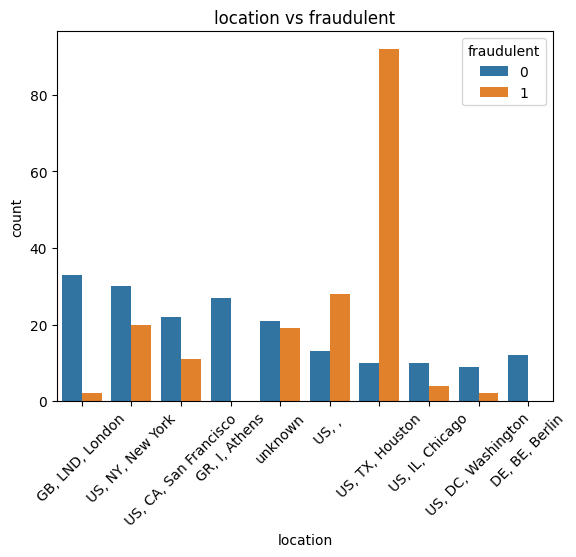

In [37]:
for col in cat_cols:
    plt.xticks(rotation=45)
    sns.countplot(data=data_balanced, x=col, hue="fraudulent", order=data[col].value_counts().index[:10])
    plt.title("{} vs fraudulent".format(col))
    plt.show()

### Word Cloud

In [38]:
from wordcloud import WordCloud

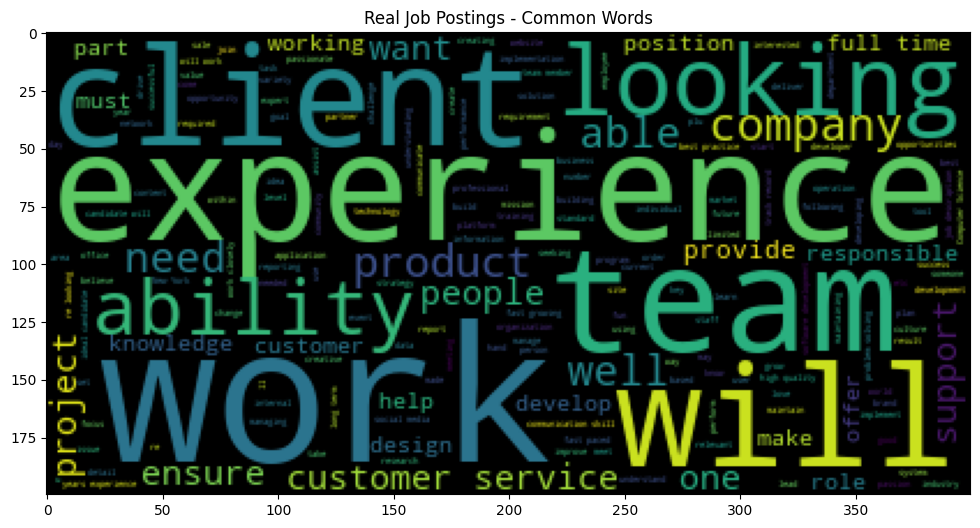

In [39]:
fake_text = " ".join(data[data["fraudulent"] == 1]["text"])
real_text = " ".join(data[data["fraudulent"] == 0]["text"])

plt.figure(figsize=(15, 6))

wc = WordCloud().generate(fake_text)
plt.title('Fake Job Postings - Common Words')
plt.imshow(wc)

real_wc = WordCloud().generate(real_text)
plt.title('Real Job Postings - Common Words')
plt.imshow(real_wc)

plt.show()

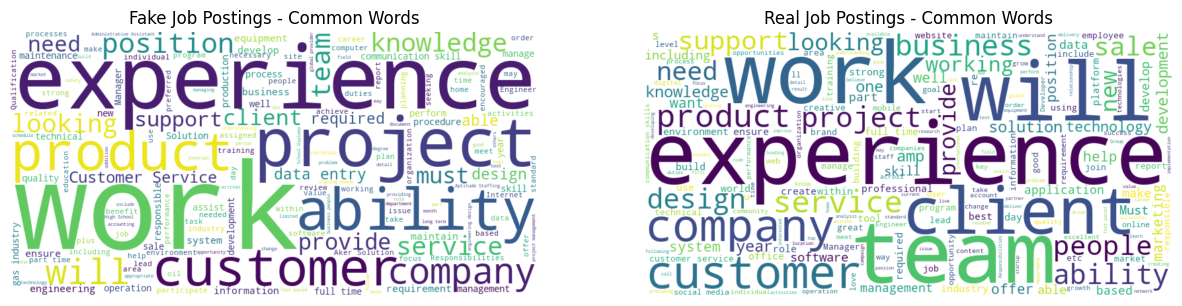

In [40]:
from wordcloud import WordCloud

fake_text = " ".join(data_balanced[data_balanced['fraudulent']==1]['text'].dropna())
real_text = " ".join(data_balanced[data_balanced['fraudulent']==0]['text'].dropna())

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
wc = WordCloud(width=800, height=400, background_color='white').generate(fake_text)
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Fake Job Postings - Common Words')

plt.subplot(1, 2, 2)
wc = WordCloud(width=800, height=400, background_color='white').generate(real_text)
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Real Job Postings - Common Words')

plt.show()


### Correlation Heat Map
For numeric features

1. Imbalaned Data

Text(0.5, 1.0, 'Correlation Heatmap')

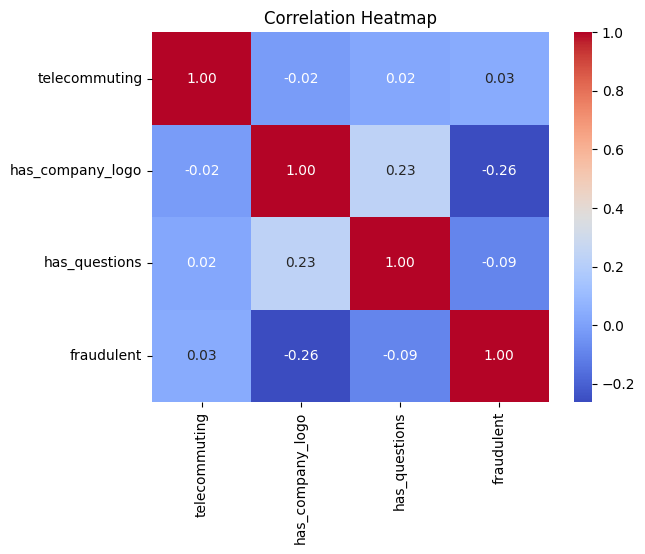

In [41]:
numeric_features = data.select_dtypes(include=['int64', 'float64']).drop(columns="job_id")

sns.heatmap(numeric_features.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')

2. Balanced Data

Text(0.5, 1.0, 'Correlation Heatmap')

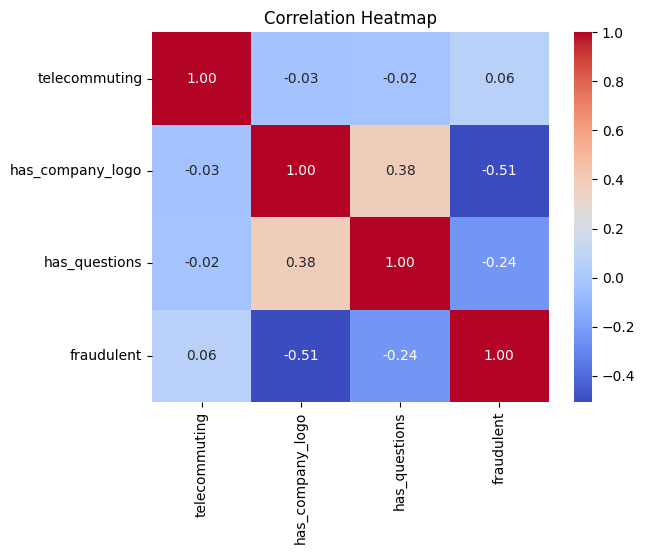

In [42]:
numeric_features = data_balanced.select_dtypes(include=['int64', 'float64']).drop(columns="job_id")

sns.heatmap(numeric_features.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')

In [43]:
data[["text"]]

,text
0,"Marketing Intern We're Food52, and we've creat..."
1,Customer Service - Cloud Video Production 90 S...
2,Commissioning Machinery Assistant (CMA) Valor ...
3,Account Executive - Washington DC Our passion ...
4,Bill Review Manager SpotSource Solutions LLC i...
...,...
17875,Account Director - Distribution Vend is looki...
17876,Payroll Accountant WebLinc is the e-commerce p...
17877,Project Cost Control Staff Engineer - Cost Con...
17878,Graphic Designer Nemsia Studios is looking fo...


## Text Preprocessing

In [44]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords")
nltk.download("punkt")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download('punkt_tab')

stop_words = stopwords.words("english")
lemmatizer = WordNetLemmatizer()

def text_preprocessing(text):
    
    #lower casing
    text = text.lower()
        
    # Remove stop words
    text = " ".join([word for word in text.split() if word not in stop_words]) 
        
    #Removing punctuations
    text = re.sub(r"[^a-z\s]", " ", text)
    
    # Tokenize
    tokens = nltk.word_tokenize(text)
        
    #lemmatization
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    
    #joining back the string
    return " ".join(tokens)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\huzef\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\huzef\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\huzef\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\huzef\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\huzef\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Minimal preprocessing returned better results because stop words and some punctuations contribute to determining whether a job is real or fake
For example: if a job mentioned "No experience required" it will be transformed to "Experience required" after stop words removal.

In [45]:
def minimal_preprocessing(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    
    # Tokenize
    tokens = nltk.word_tokenize(text)
        
    #lemmatization
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    
    #joining back the string
    return " ".join(tokens)

In [46]:
for word in stop_words:
    print(word)

a
about
above
after
again
against
ain
all
am
an
and
any
are
aren
aren't
as
at
be
because
been
before
being
below
between
both
but
by
can
couldn
couldn't
d
did
didn
didn't
do
does
doesn
doesn't
doing
don
don't
down
during
each
few
for
from
further
had
hadn
hadn't
has
hasn
hasn't
have
haven
haven't
having
he
he'd
he'll
her
here
hers
herself
he's
him
himself
his
how
i
i'd
if
i'll
i'm
in
into
is
isn
isn't
it
it'd
it'll
it's
its
itself
i've
just
ll
m
ma
me
mightn
mightn't
more
most
mustn
mustn't
my
myself
needn
needn't
no
nor
not
now
o
of
off
on
once
only
or
other
our
ours
ourselves
out
over
own
re
s
same
shan
shan't
she
she'd
she'll
she's
should
shouldn
shouldn't
should've
so
some
such
t
than
that
that'll
the
their
theirs
them
themselves
then
there
these
they
they'd
they'll
they're
they've
this
those
through
to
too
under
until
up
ve
very
was
wasn
wasn't
we
we'd
we'll
we're
were
weren
weren't
we've
what
when
where
which
while
who
whom
why
will
with
won
won't
wouldn
wouldn't
y
you
you'd
you'

In [47]:
data["cleaned_text"] = data["text"].apply(minimal_preprocessing)

In [48]:
data

,job_id,location,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,text,cleaned_text
0,1,"US, NY, New York",0,1,0,Other,Internship,unknown,unknown,Marketing,0,"Marketing Intern We're Food52, and we've creat...","marketing intern we 're food52 , and we 've cr..."
1,2,"NZ, , Auckland",0,1,0,Full-time,Not Applicable,unknown,Marketing and Advertising,Customer Service,0,Customer Service - Cloud Video Production 90 S...,customer service - cloud video production 90 s...
2,3,"US, IA, Wever",0,1,0,unknown,unknown,unknown,unknown,unknown,0,Commissioning Machinery Assistant (CMA) Valor ...,commissioning machinery assistant ( cma ) valo...
3,4,"US, DC, Washington",0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0,Account Executive - Washington DC Our passion ...,account executive - washington dc our passion ...
4,5,"US, FL, Fort Worth",0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0,Bill Review Manager SpotSource Solutions LLC i...,bill review manager spotsource solution llc is...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
17875,17876,"CA, ON, Toronto",0,1,1,Full-time,Mid-Senior level,unknown,Computer Software,Sales,0,Account Director - Distribution Vend is looki...,account director - distribution vend is lookin...
17876,17877,"US, PA, Philadelphia",0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Internet,Accounting/Auditing,0,Payroll Accountant WebLinc is the e-commerce p...,payroll accountant weblinc is the e-commerce p...
17877,17878,"US, TX, Houston",0,0,0,Full-time,unknown,unknown,unknown,unknown,0,Project Cost Control Staff Engineer - Cost Con...,project cost control staff engineer - cost con...
17878,17879,"NG, LA, Lagos",0,0,1,Contract,Not Applicable,Professional,Graphic Design,Design,0,Graphic Designer Nemsia Studios is looking fo...,graphic designer nemsia studio is looking for ...


In [49]:
data[["text", "cleaned_text"]].iloc[0]

text            Marketing Intern We're Food52, and we've creat...
cleaned_text    marketing intern we 're food52 , and we 've cr...
Name: 0, dtype: object

In [50]:
data["text"][0]

"Marketing Intern We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.We have a top editorial, business, and engineering team. We're focused on using technology to find new and better ways to connect people around their specific food interests, and to offer them superb, highly curated information about food and cooking. We attract the most talented home cooks and contributors in the country; we also publish well-known professionals like Mario Batali, Gwyneth Paltrow, and Danny Meyer. And we have partnerships with Whole Foods Market and Random House.Food52 has been named the best food website by the James Beard Foundation and IACP, and has been featured in the New York Times, NPR, Pando Daily, TechCrunch, and on the Today Show.We're located in Chelsea, in New York City. Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and cu

In [51]:
data["cleaned_text"][0]

"marketing intern we 're food52 , and we 've created a groundbreaking and award-winning cooking site . we support , connect , and celebrate home cook , and give them everything they need in one place.we have a top editorial , business , and engineering team . we 're focused on using technology to find new and better way to connect people around their specific food interest , and to offer them superb , highly curated information about food and cooking . we attract the most talented home cook and contributor in the country ; we also publish well-known professional like mario batali , gwyneth paltrow , and danny meyer . and we have partnership with whole food market and random house.food52 ha been named the best food website by the james beard foundation and iacp , and ha been featured in the new york time , npr , pando daily , techcrunch , and on the today show.we 're located in chelsea , in new york city . food52 , a fast-growing , james beard award-winning online food community and cro

In [52]:
data.head()

,job_id,location,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,text,cleaned_text
0,1,"US, NY, New York",0,1,0,Other,Internship,unknown,unknown,Marketing,0,"Marketing Intern We're Food52, and we've creat...","marketing intern we 're food52 , and we 've cr..."
1,2,"NZ, , Auckland",0,1,0,Full-time,Not Applicable,unknown,Marketing and Advertising,Customer Service,0,Customer Service - Cloud Video Production 90 S...,customer service - cloud video production 90 s...
2,3,"US, IA, Wever",0,1,0,unknown,unknown,unknown,unknown,unknown,0,Commissioning Machinery Assistant (CMA) Valor ...,commissioning machinery assistant ( cma ) valo...
3,4,"US, DC, Washington",0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0,Account Executive - Washington DC Our passion ...,account executive - washington dc our passion ...
4,5,"US, FL, Fort Worth",0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0,Bill Review Manager SpotSource Solutions LLC i...,bill review manager spotsource solution llc is...


## Training the Model

Here we're not using the balanced dataset, we're using the original dataset and the stratify feature in train_test_split

In [53]:
from sklearn.model_selection import train_test_split

X = data["cleaned_text"]
y = data["fraudulent"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Let's first transform the our data into word vectors that the linear SVC model will use for further processing

In [54]:
from sklearn.feature_extraction.text import TfidfVectorizer

#tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2))

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2),
    min_df=5,
    max_df=0.9
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

training the model and evaluating performance

In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.svm import LinearSVC

#model = LogisticRegression(max_iter=1000, class_weight="balanced")
model = LinearSVC(class_weight='balanced')
model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9840604026845637
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3403
           1       0.80      0.90      0.85       173

    accuracy                           0.98      3576
   macro avg       0.90      0.94      0.92      3576
weighted avg       0.99      0.98      0.98      3576



In [56]:
from sklearn.metrics import precision_recall_curve

probs = model.decision_function(X_test_tfidf)
prec, rec, thresh = precision_recall_curve(y_test, probs)

In [57]:
print(confusion_matrix(y_test,y_pred))

[[3363   40]
 [  17  156]]


In [58]:
false_negatives = X_test[(y_test == 1) & (y_pred ==0)]

In [59]:
false_negatives

12104    production manager heavy duty diesel 2022 2022...
6984     hr process leader position summary : expro ’ s...
4593     code compliance officer the accion story began...
6974     manager of project management organization - e...
17720    finance assistant on behalf of our client we a...
3463     business development manager we are currently ...
5926     assistant accountant looking for an assistant ...
4668     human resource director a the industry ’ s lar...
5672     software design engineer software design engin...
17778    director of nursing apply using below link # u...
11587    seo analysis bright edge and aptitude staffing...
7492     rnfa registered nurse first assistant apply us...
4761     company representative needed our motherless w...
8595     clinical director apply using below link # url...
17566    clinical director - surgical service apply usi...
17615    accounting clerk ( $ 20/hr ) maverick fx , est...
17788    administrative specialist ii find more job at .

In [60]:
false_negatives.shape

(17,)

In [61]:
false_negative_indices = false_negatives.index

In [62]:
false_negative_data = data.loc[false_negative_indices, [
    "job_id",
    "location",
    "telecommuting",
    "has_company_logo",
    "has_questions",
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function",
    "text"
]]

In [63]:
false_negative_data

,job_id,location,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,text
12104,12105,"US, TN, Morristown",0,0,0,Full-time,unknown,unknown,unknown,unknown,Production Manager Heavy Duty Diesel 2022 20...
6984,6985,"US, TX, Houston",0,0,0,Full-time,unknown,unknown,Oil & Energy,Human Resources,HR PROCESS LEADER Position Summary:EXPRO’s Gl...
4593,4594,"US, OK, Oklahoma City",0,1,1,Full-time,Entry level,High School or equivalent,Public Safety,Public Relations,Code Compliance Officer The Accion story bega...
6974,6975,"US, TX, Houston",0,0,0,Full-time,unknown,unknown,Oil & Energy,Project Management,Manager of Project Management Organization -...
17720,17721,"AU, NSW, Sydney",0,0,0,Part-time,Not Applicable,unknown,Financial Services,Finance,Finance Assistant On behalf of our client we ...
3463,3464,"US, CA, San Francisco",0,0,1,Full-time,unknown,High School or equivalent,Wholesale,Sales,Business Development Manager We are currently...
5926,5927,"AU, ,",0,0,0,Part-time,unknown,unknown,Financial Services,Finance,Assistant Accountant Looking for an Assistant...
4668,4669,"US, TX, AUSTIN",0,1,1,Full-time,Director,High School or equivalent,Human Resources,Human Resources,Human Resource Director As the industry’s larg...
5672,5673,"US, CA, Palo Alto",0,0,1,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Engineering,Software Design Engineer Software Design Engi...
17778,17779,"US, DE,",0,0,0,Full-time,unknown,unknown,Hospital & Health Care,unknown,Director of Nursing Apply using below link#...


In [64]:
false_negative_data[[
    "location",
    "telecommuting",
    "has_company_logo",
    "has_questions",
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]]

,location,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function
12104,"US, TN, Morristown",0,0,0,Full-time,unknown,unknown,unknown,unknown
6984,"US, TX, Houston",0,0,0,Full-time,unknown,unknown,Oil & Energy,Human Resources
4593,"US, OK, Oklahoma City",0,1,1,Full-time,Entry level,High School or equivalent,Public Safety,Public Relations
6974,"US, TX, Houston",0,0,0,Full-time,unknown,unknown,Oil & Energy,Project Management
17720,"AU, NSW, Sydney",0,0,0,Part-time,Not Applicable,unknown,Financial Services,Finance
3463,"US, CA, San Francisco",0,0,1,Full-time,unknown,High School or equivalent,Wholesale,Sales
5926,"AU, ,",0,0,0,Part-time,unknown,unknown,Financial Services,Finance
4668,"US, TX, AUSTIN",0,1,1,Full-time,Director,High School or equivalent,Human Resources,Human Resources
5672,"US, CA, Palo Alto",0,0,1,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Engineering
17778,"US, DE,",0,0,0,Full-time,unknown,unknown,Hospital & Health Care,unknown


In [65]:
false_negative_data["text"].iloc[0]

"Production Manager Heavy Duty Diesel  2022  2022Job Title: Production Manager Heavy Duty DieselRole: Engineering or RelatedRelocation Available: YesIndustry: ManufacturingLocation: TennesseeTown / City: MorristownJob Type: Permanent full-timeJob description:The Production Manager is responsible for a specified section or department(s) of the Heavy Duty Piston Operations Business Unit. The specified section is typically comprised of six to ten production cost centers for machining, surface treatment processes, and/or inspection/assembly processes.\xa0The primary responsibilities of the Diesel Production Manager:1.) Production\xa0Operations (machining, product surface treatment, and/or inspection/assembly processes)The Manager of the specific department(s) of the business unit has responsibility for its performance. This includes Product Quality, operational efficiency, staffing of salary and hourly positions, production scheduling, capacity utilization, control of costs (labor, operati

In [66]:
for i, idx in enumerate(false_negative_indices):
    print(f"\n{'='*80}")
    print(f"FALSE NEGATIVE {i+1} | INDEX: {idx}\n")
    print(false_negative_data.loc[idx, "text"][:1000])


FALSE NEGATIVE 1 | INDEX: 12104

Production Manager Heavy Duty Diesel  2022  2022Job Title: Production Manager Heavy Duty DieselRole: Engineering or RelatedRelocation Available: YesIndustry: ManufacturingLocation: TennesseeTown / City: MorristownJob Type: Permanent full-timeJob description:The Production Manager is responsible for a specified section or department(s) of the Heavy Duty Piston Operations Business Unit. The specified section is typically comprised of six to ten production cost centers for machining, surface treatment processes, and/or inspection/assembly processes. The primary responsibilities of the Diesel Production Manager:1.) Production Operations (machining, product surface treatment, and/or inspection/assembly processes)The Manager of the specific department(s) of the business unit has responsibility for its performance. This includes Product Quality, operational efficiency, staffing of salary and hourly positions, production scheduling, capacity utilization, contr

In [67]:
feature_names = tfidf.get_feature_names_out()

In [68]:
feature_names

array(['00', '000', '0in', ..., 'να', 'σε', 'το'], dtype=object)

In [69]:
coefficients = model.coef_[0]
coefficients

array([-0.25349205,  1.04845211,  0.54539527, ..., -0.16276343,
       -0.17983181, -0.09258432])

In [70]:
feature_importance = pd.DataFrame({"Feature": feature_names, "Coefficient": coefficients})

In [71]:
feature_importance

,Feature,Coefficient
0,00,-0.253492
1,000,1.048452
2,0in,0.545395
3,10,0.793146
4,10 year,0.708691
...,...,...
4995,και,-0.594480
4996,με,-0.158554
4997,να,-0.162763
4998,σε,-0.179832


In [72]:
feature_importance.sort_values("Coefficient",ascending=False).head(30)

,Feature,Coefficient
2475,link,2.668131
2896,offshore,2.459552
529,aptitude,2.234086
702,below,1.958963
81,accountant,1.814224
2002,high school,1.788475
4020,systems,1.787974
917,clerk,1.750369
2078,immediate,1.719927
3789,signing,1.618039


In [73]:
y_score = model.decision_function(tfidf.transform(X_test))

In [74]:
y_score

array([-0.76621767, -0.85657028, -1.44101242, ..., -0.87117567,
       -1.56632599, -2.04858354])

In [75]:
false_negative_scores = y_score[(y_test == 1) & (y_pred == 0)]

false_negative_scores

array([-0.01069394, -0.46852242, -0.0519678 , -0.09004853, -0.02657361,
       -0.8450714 , -0.33983337, -0.11487432, -1.36066176, -0.03033049,
       -0.14710116, -0.08669639, -0.48345775, -0.10848265, -0.59201679,
       -0.36470215, -0.32170248])

In [76]:
false_negative_analysis = false_negative_data.copy()

false_negative_analysis["decision_score"] = false_negative_scores

false_negative_analysis[[
    "job_id",
    "decision_score",
    "location",
    "telecommuting",
    "has_company_logo",
    "has_questions",
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]]

,job_id,decision_score,location,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function
12104,12105,-0.010694,"US, TN, Morristown",0,0,0,Full-time,unknown,unknown,unknown,unknown
6984,6985,-0.468522,"US, TX, Houston",0,0,0,Full-time,unknown,unknown,Oil & Energy,Human Resources
4593,4594,-0.051968,"US, OK, Oklahoma City",0,1,1,Full-time,Entry level,High School or equivalent,Public Safety,Public Relations
6974,6975,-0.090049,"US, TX, Houston",0,0,0,Full-time,unknown,unknown,Oil & Energy,Project Management
17720,17721,-0.026574,"AU, NSW, Sydney",0,0,0,Part-time,Not Applicable,unknown,Financial Services,Finance
3463,3464,-0.845071,"US, CA, San Francisco",0,0,1,Full-time,unknown,High School or equivalent,Wholesale,Sales
5926,5927,-0.339833,"AU, ,",0,0,0,Part-time,unknown,unknown,Financial Services,Finance
4668,4669,-0.114874,"US, TX, AUSTIN",0,1,1,Full-time,Director,High School or equivalent,Human Resources,Human Resources
5672,5673,-1.360662,"US, CA, Palo Alto",0,0,1,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Engineering
17778,17779,-0.030330,"US, DE,",0,0,0,Full-time,unknown,unknown,Hospital & Health Care,unknown


Notice how these false negative decision scores are very close to 0. Which means our model almost predictied correctly. It wasn't very confused

In [77]:
false_negative_analysis.sort_values("decision_score")

,job_id,location,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,text,decision_score
5672,5673,"US, CA, Palo Alto",0,0,1,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Engineering,Software Design Engineer Software Design Engi...,-1.360662
3463,3464,"US, CA, San Francisco",0,0,1,Full-time,unknown,High School or equivalent,Wholesale,Sales,Business Development Manager We are currently...,-0.845071
17566,17567,"US, PA,",0,0,0,Full-time,unknown,unknown,Hospital & Health Care,unknown,Clinical Director - Surgical Services Apply...,-0.592017
4761,4762,"US, NY, mumford",0,0,1,Contract,Not Applicable,High School or equivalent,Civic & Social Organization,Finance,COMPANY REPRESENTATIVE NEEDED Our motherless ...,-0.483458
6984,6985,"US, TX, Houston",0,0,0,Full-time,unknown,unknown,Oil & Energy,Human Resources,HR PROCESS LEADER Position Summary:EXPRO’s Gl...,-0.468522
17615,17616,"US, NY, New York",0,0,0,Full-time,Entry level,High School or equivalent,Accounting,Accounting/Auditing,"Accounting Clerk($20/hr) Maverick FX, establi...",-0.364702
5926,5927,"AU, ,",0,0,0,Part-time,unknown,unknown,Financial Services,Finance,Assistant Accountant Looking for an Assistant...,-0.339833
17788,17789,"US, KY,",0,0,0,unknown,unknown,unknown,unknown,unknown,Administrative Specialist II Find more jobs...,-0.321702
11587,11588,"US, CA, San Mateo",0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Marketing and Advertising,Information Technology,SEO Analysis Bright Edge and Aptitude Staffing...,-0.147101
4668,4669,"US, TX, AUSTIN",0,1,1,Full-time,Director,High School or equivalent,Human Resources,Human Resources,Human Resource Director As the industry’s larg...,-0.114874


In [78]:
false_negative_analysis[["job_id", "decision_score", "text"]]

,job_id,decision_score,text
12104,12105,-0.010694,Production Manager Heavy Duty Diesel 2022 20...
6984,6985,-0.468522,HR PROCESS LEADER Position Summary:EXPRO’s Gl...
4593,4594,-0.051968,Code Compliance Officer The Accion story bega...
6974,6975,-0.090049,Manager of Project Management Organization -...
17720,17721,-0.026574,Finance Assistant On behalf of our client we ...
3463,3464,-0.845071,Business Development Manager We are currently...
5926,5927,-0.339833,Assistant Accountant Looking for an Assistant...
4668,4669,-0.114874,Human Resource Director As the industry’s larg...
5672,5673,-1.360662,Software Design Engineer Software Design Engi...
17778,17779,-0.030330,Director of Nursing Apply using below link#...


### Changing the threshold to finetune the results

In [79]:
y_pred_threshold = (y_score >= -0.1).astype(int)

In [80]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_test, y_pred_threshold))
print(classification_report(y_test, y_pred_threshold))

[[3349   54]
 [  11  162]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      3403
           1       0.75      0.94      0.83       173

    accuracy                           0.98      3576
   macro avg       0.87      0.96      0.91      3576
weighted avg       0.98      0.98      0.98      3576



In [81]:
y_score = model.decision_function(X_test_tfidf)

In [82]:
import numpy as np
thresholds = list(np.arange(-1.0, 1.1, 0.1))

In [83]:
for threshold in thresholds:
    y_pred_threshold = (y_score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_threshold).ravel()
    
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    
    f1 = 2 * (precision * recall) / (precision + recall)
    
    print(
        f"Threshold: {threshold:>4} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f} | "
        f"FP: {fp:3} | FN: {fn:3}"
    )

Threshold: -1.0 | Precision: 0.192 | Recall: 0.994 | F1: 0.322 | FP: 722 | FN:   1
Threshold: -0.9 | Precision: 0.242 | Recall: 0.994 | F1: 0.390 | FP: 538 | FN:   1
Threshold: -0.8 | Precision: 0.297 | Recall: 0.988 | F1: 0.457 | FP: 404 | FN:   2
Threshold: -0.7000000000000001 | Precision: 0.359 | Recall: 0.988 | F1: 0.527 | FP: 305 | FN:   2
Threshold: -0.6000000000000001 | Precision: 0.418 | Recall: 0.988 | F1: 0.588 | FP: 238 | FN:   2
Threshold: -0.5000000000000001 | Precision: 0.483 | Recall: 0.983 | F1: 0.648 | FP: 182 | FN:   3
Threshold: -0.40000000000000013 | Precision: 0.573 | Recall: 0.971 | F1: 0.721 | FP: 125 | FN:   5
Threshold: -0.30000000000000016 | Precision: 0.642 | Recall: 0.954 | F1: 0.767 | FP:  92 | FN:   8
Threshold: -0.20000000000000018 | Precision: 0.711 | Recall: 0.954 | F1: 0.815 | FP:  67 | FN:   8
Threshold: -0.1000000000000002 | Precision: 0.750 | Recall: 0.936 | F1: 0.833 | FP:  54 | FN:  11
Threshold: -2.220446049250313e-16 | Precision: 0.796 | Recall:

In [84]:
thresholds = np.arange(-0.2, 0.11, 0.01)
results = []

for threshold in thresholds:
    y_pred_threshold = (y_score >= threshold).astype(int)
    
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_threshold).ravel()
    
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    
    f1 = 2 * (precision * recall) / (precision + recall)
    
    results.append({
       "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "FP": fp,
        "FN": fn
    })
    
    
resultsdf = pd.DataFrame(results)
resultsdf

,Threshold,Precision,Recall,F1,FP,FN
0,-2.000000e-01,0.711207,0.953757,0.814815,67,8
1,-1.900000e-01,0.723684,0.953757,0.822943,63,8
2,-1.800000e-01,0.723684,0.953757,0.822943,63,8
3,-1.700000e-01,0.726872,0.953757,0.825000,62,8
4,-1.600000e-01,0.733333,0.953757,0.829146,60,8
5,-1.500000e-01,0.736607,0.953757,0.831234,59,8
6,-1.400000e-01,0.735426,0.947977,0.828283,59,9
7,-1.300000e-01,0.742081,0.947977,0.832487,57,9
8,-1.200000e-01,0.745455,0.947977,0.834606,56,9
9,-1.100000e-01,0.747706,0.942197,0.833760,55,10


## Additional Testing

In [104]:
tfidf_test = TfidfVectorizer(max_features=10000,
    ngram_range=(1,3),
    min_df=5,
    max_df=0.9
)
X_train_1 = tfidf_test.fit_transform(X_train)
X_test_1 = tfidf_test.transform(X_test)

In [105]:
model = LinearSVC(class_weight='balanced')
model.fit(X_train_1, y_train)

y_pred_1 = model.predict(X_test_1)

In [95]:
confusion_matrix(y_test, y_pred_1)

array([[3363,   40],
       [  17,  156]], dtype=int64)

In [96]:
print("Accuracy:", accuracy_score(y_test, y_pred_1))

Accuracy: 0.9840604026845637


In [99]:
confusion_matrix(y_test, y_pred_1)

array([[3374,   29],
       [  18,  155]], dtype=int64)

In [100]:
print("Accuracy:", accuracy_score(y_test, y_pred_1))

Accuracy: 0.9868568232662193


In [103]:
confusion_matrix(y_test, y_pred_1)

array([[3381,   22],
       [  18,  155]], dtype=int64)

In [106]:
confusion_matrix(y_test, y_pred_1)

array([[3375,   28],
       [  17,  156]], dtype=int64)